## Subquestion 5

*What is the difference between the predicted trend of traffic accidents in Amsterdam from 2023-now (if there was no intervention) compared to the real data?*

We fit a trend on the years before the 30 km/h change, extrapolate it to 2024–2025 and compare it with the actual counts.

### Step 1 - Load data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

df = pd.read_csv("data/crashes_amsterdam_classified.csv", low_memory=False)

CHANGE = 2023.5   # 30 km/h introduced in December 2023 (between the yearly points)

### Step 2 - Accidents per year

Only the year of each accident is available (the date and time columns are empty), so we use yearly counts. Three series:
- All of Amsterdam: every accident.
- City roads: all accidents except road group `other`, which is mostly highways (80 km/h or more) that were not part of the change.
- 50->30 roads: the roads where the limit was lowered.

In [2]:
city = df["ROAD_GROUP"] != "other"
counts = pd.DataFrame({
    "All of Amsterdam": df.groupby("JAAR_VKL").size(),
    "City roads": df[city].groupby("JAAR_VKL").size(),
    "50->30 roads": df[df["ROAD_GROUP"] == "50->30"].groupby("JAAR_VKL").size(),
})
counts.index.name = "year"
SERIES_COLOURS = dict(zip(counts.columns, ["C0", "C1", "C2"]))
display(counts)

,All of Amsterdam,City roads,50->30 roads
year,,,
2016,6811,5276,2199
2017,6884,5151,2211
2018,7156,4911,1989
2019,7142,4568,1857
2020,5018,3385,1429
2021,5317,3799,1587
2022,5979,4330,1775
2023,6813,4544,1783
2024,6201,4075,1616


Figure 1 splits the total into city roads and highways. Before COVID, accidents on highways went up while accidents on city roads went down, so the total hides the trend on the city roads.

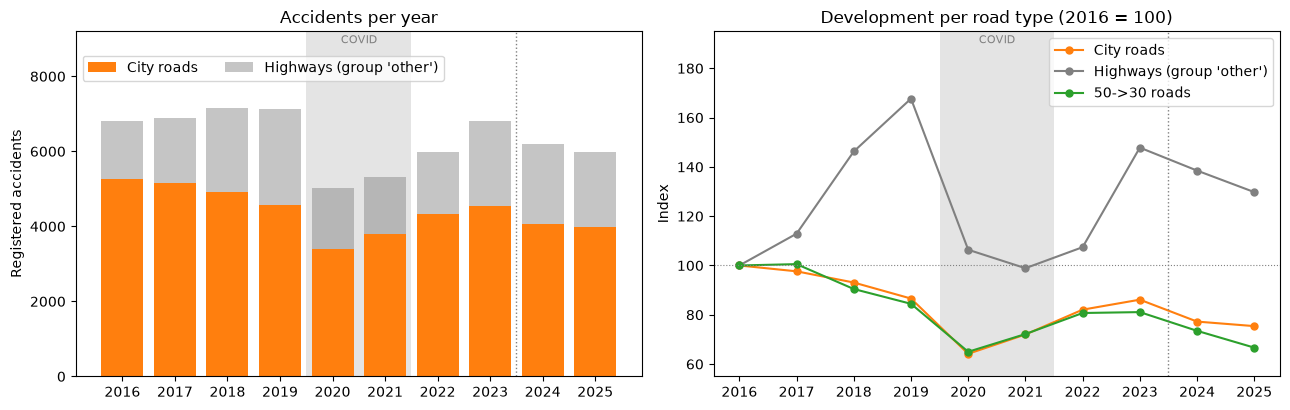

In [3]:
highways = df[~city].groupby("JAAR_VKL").size()
split = pd.DataFrame({"City roads": counts["City roads"], "Highways (group 'other')": highways,
                      "50->30 roads": counts["50->30 roads"]})
indexed = split / split.loc[2016] * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
ax.bar(split.index, split["City roads"], color="C1", label="City roads")
ax.bar(split.index, split["Highways (group 'other')"], bottom=split["City roads"], color="grey", alpha=0.45,
       label="Highways (group 'other')")
ax.set_title("Accidents per year")
ax.set_ylabel("Registered accidents")
ax.set_ylim(0, 9200)
ax.legend(loc="upper left", ncol=2, bbox_to_anchor=(0, 0.95))

ax = axes[1]
for name, colour in zip(indexed.columns, ["C1", "grey", "C2"]):
    ax.plot(indexed.index, indexed[name], color=colour, marker="o", ms=5, label=name)
ax.axhline(100, color="grey", lw=0.8, ls=":")
ax.set_title("Development per road type (2016 = 100)")
ax.set_ylabel("Index")
ax.set_ylim(55, 195)
ax.legend(loc="upper right")

for ax in axes:
    ax.axvspan(2019.5, 2021.5, color="lightgrey", alpha=0.6, lw=0, zorder=0)
    ax.text(2020.5, 0.99, "COVID", transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=8, color="grey")
    ax.axvline(CHANGE, color="grey", ls=":", lw=1)
    ax.set_xticks(split.index)
fig.tight_layout()
fig.savefig("RQ5_accidents_per_year.png", dpi=150)
plt.show()

### Step 3 - Trend model

A Poisson regression of the yearly count on the year (log link), so the trend is a constant percentage change per year. Year-to-year variation is larger than Poisson assumes, so we scale the uncertainty with an estimated dispersion factor $\phi$ (quasi-Poisson). The 95% prediction interval includes both the uncertainty of the trend and normal year-to-year variation.

Pre-period: 2016–2019, 2022 and 2023. COVID years 2020–2021 are left out; 2023 is included because 11 of its 12 months are before the change.

In [4]:
PRE_YEARS = [2016, 2017, 2018, 2019, 2022, 2023]
POST_YEARS = [2024, 2025]


def design(years):
    years = np.asarray(years, dtype=float)
    return np.column_stack([np.ones(len(years)), years - 2016])


def fit_poisson_trend(years, y):
    """Quasi-Poisson regression of counts on year (fitted with IRLS)."""
    X, y = design(years), np.asarray(y, dtype=float)
    beta = np.array([np.log(y.mean()), 0.0])
    for _ in range(100):
        mu = np.exp(X @ beta)
        z = X @ beta + (y - mu) / mu
        new_beta = np.linalg.solve(X.T @ (mu[:, None] * X), X.T @ (mu * z))
        if np.allclose(new_beta, beta, rtol=1e-10):
            break
        beta = new_beta
    mu = np.exp(X @ beta)
    dof = len(y) - X.shape[1]
    phi = max(1.0, np.sum((y - mu) ** 2 / mu) / dof)
    cov = phi * np.linalg.inv(X.T @ (mu[:, None] * X))
    return {"beta": beta, "cov": cov, "phi": phi, "dof": dof}


def predict(model, years, level=0.95):
    """Expected count and prediction interval."""
    X = design(years)
    mu = np.exp(X @ model["beta"])
    se = np.sqrt(mu ** 2 * np.einsum("ij,jk,ik->i", X, model["cov"], X) + model["phi"] * mu)
    t = stats.t.ppf((1 + level) / 2, model["dof"])
    return pd.DataFrame({"predicted": mu, "lower": mu - t * se, "upper": mu + t * se},
                        index=pd.Index(years, name="year"))


models = {name: fit_poisson_trend(PRE_YEARS, counts.loc[PRE_YEARS, name]) for name in counts.columns}
pd.DataFrame({name: {"trend_%_per_year": np.expm1(m["beta"][1]) * 100, "dispersion_phi": m["phi"]}
              for name, m in models.items()}).T.round(1)

,trend_%_per_year,dispersion_phi
All of Amsterdam,-1.1,26.3
City roads,-2.5,7.0
50->30 roads,-3.3,3.8


### Step 4 - Predicted vs. actual

In [5]:
rows = []
for name in counts.columns:
    p = predict(models[name], POST_YEARS)
    p["actual"] = counts.loc[POST_YEARS, name].values
    p["difference_%"] = 100 * (p["actual"] - p["predicted"]) / p["predicted"]
    p["inside_interval"] = p["actual"].between(p["lower"], p["upper"])
    rows.append(p.reset_index().assign(series=name))
comparison = pd.concat(rows, ignore_index=True).set_index(["series", "year"])
display(comparison.round({"predicted": 0, "lower": 0, "upper": 0, "difference_%": 1}))

predicted   lower   upper  actual  difference_%  \
series           year                                                    
All of Amsterdam 2024     6434.0  4924.0  7944.0    6201          -3.6   
                 2025     6361.0  4754.0  7969.0    5970          -6.2   
City roads       2024     4234.0  3605.0  4862.0    4075          -3.7   
                 2025     4128.0  3467.0  4789.0    3978          -3.6   
50->30 roads     2024     1668.0  1380.0  1957.0    1616          -3.1   
                 2025     1613.0  1312.0  1915.0    1466          -9.1   

                       inside_interval  
series           year                   
All of Amsterdam 2024             True  
                 2025             True  
City roads       2024             True  
                 2025             True  
50->30 roads     2024             True  
                 2025             True

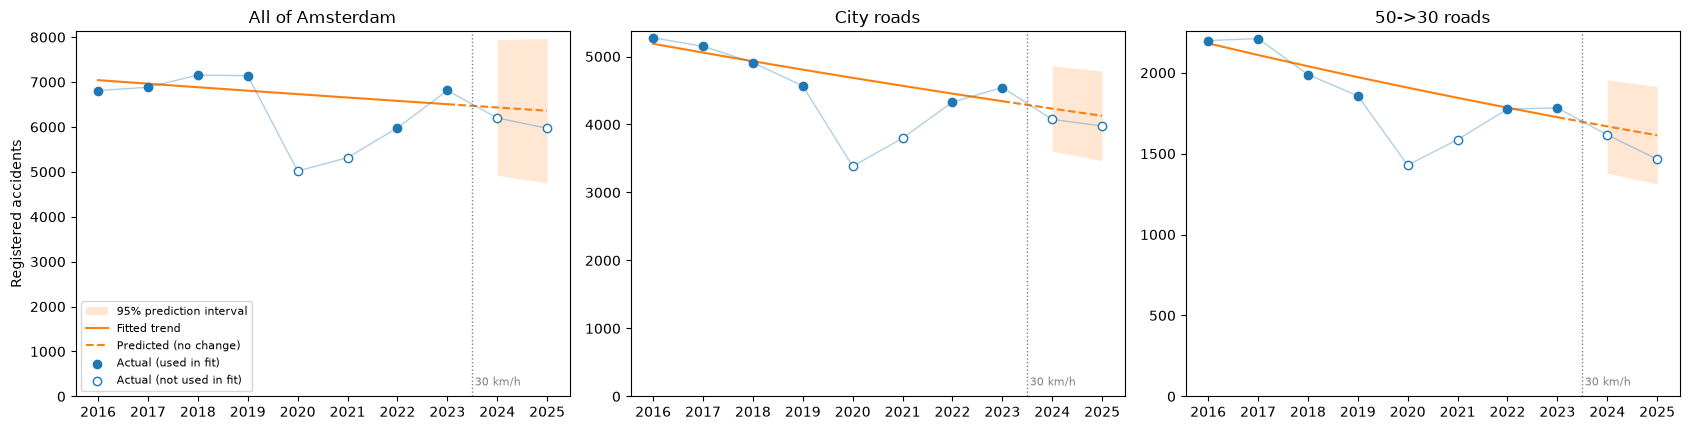

In [6]:
line_years = np.arange(2016, 2026)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))

for ax, name in zip(axes, counts.columns):
    p = predict(models[name], line_years)
    ax.fill_between(POST_YEARS, p.loc[POST_YEARS, "lower"], p.loc[POST_YEARS, "upper"],
                    color="C1", alpha=0.18, lw=0, label="95% prediction interval")
    ax.plot(p.loc[:2023].index, p.loc[:2023, "predicted"], color="C1", label="Fitted trend")
    ax.plot(p.loc[2023:].index, p.loc[2023:, "predicted"], color="C1", ls="--", label="Predicted (no change)")

    y = counts[name]
    used = y.index.isin(PRE_YEARS)
    ax.plot(y.index, y.values, color="C0", lw=1, alpha=0.35)
    ax.scatter(y.index[used], y[used], color="C0", s=36, zorder=3,
               label="Actual (used in fit)")
    ax.scatter(y.index[~used], y[~used], facecolor="white", edgecolor="C0", s=36, zorder=3,
               label="Actual (not used in fit)")

    ax.axvline(CHANGE, color="grey", ls=":", lw=1)
    ax.text(CHANGE + 0.05, 0.03, "30 km/h", transform=ax.get_xaxis_transform(), fontsize=8, color="grey")
    ax.set_title(name)
    ax.set_xticks(line_years)
    ax.set_ylim(bottom=0)
axes[0].set_ylabel("Registered accidents")
axes[0].legend(loc="lower left", fontsize=8)
fig.tight_layout()
fig.savefig("RQ5_predicted_vs_actual.png", dpi=150)
plt.show()

Figure 3 shows the same comparison as a percentage: how far each actual count is from the prediction. The bars are the 95% prediction interval; if a bar crosses 0, the difference is within normal variation.

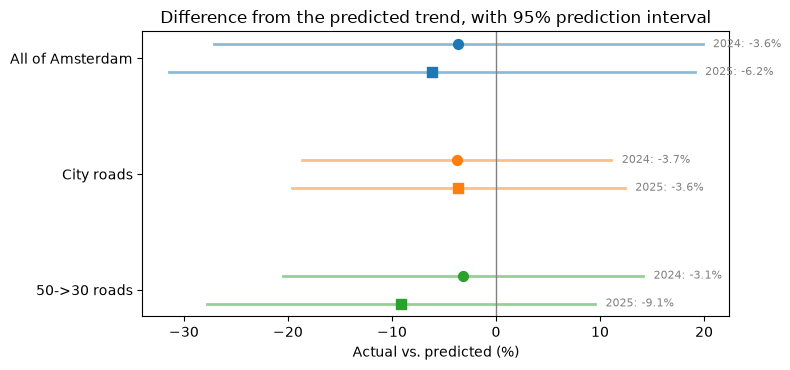

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.8))
offsets = {2024: -0.12, 2025: 0.12}
for i, name in enumerate(counts.columns):
    for year in POST_YEARS:
        r = comparison.loc[(name, year)]
        low = 100 * (r["actual"] - r["upper"]) / r["predicted"]
        high = 100 * (r["actual"] - r["lower"]) / r["predicted"]
        y = i + offsets[year]
        ax.plot([low, high], [y, y], color=SERIES_COLOURS[name], lw=2, alpha=0.5)
        ax.scatter(r["difference_%"], y, color=SERIES_COLOURS[name], s=50, zorder=3,
                   marker="o" if year == 2024 else "s")
        ax.text(high + 1, y, f"{year}: {r['difference_%']:+.1f}%", va="center", fontsize=8, color="grey")
ax.axvline(0, color="grey", lw=1)
ax.set_yticks(range(len(counts.columns)), counts.columns)
ax.invert_yaxis()
ax.set_xlabel("Actual vs. predicted (%)")
ax.set_title("Difference from the predicted trend, with 95% prediction interval")
fig.tight_layout()
fig.savefig("RQ5_difference.png", dpi=150)
plt.show()

### Step 5 - Sensitivity to the pre-period

With so few years, the trend depends on which years we use. We refit the model with four alternative pre-periods.

In [8]:
pre_periods = {
    "Main: 2016-19 + 2022-23": PRE_YEARS,
    "Without 2023": [2016, 2017, 2018, 2019, 2022],
    "Without 2022": [2016, 2017, 2018, 2019, 2023],
    "Pre-COVID only: 2016-19": [2016, 2017, 2018, 2019],
    "All years: 2016-23": list(range(2016, 2024)),
}
PERIOD_COLOURS = dict(zip(pre_periods, ["C1", "C0", "C2", "C3", "C4"]))

rows = []
for name in counts.columns:
    for label, years in pre_periods.items():
        m = fit_poisson_trend(years, counts.loc[years, name])
        p = predict(m, POST_YEARS)
        actual = counts.loc[POST_YEARS, name].values
        rows.append({"series": name, "pre-period": label,
                     "trend_%_per_year": np.expm1(m["beta"][1]) * 100,
                     "difference_%": 100 * (actual.sum() - p["predicted"].sum()) / p["predicted"].sum(),
                     "inside_interval": bool(((actual >= p["lower"]) & (actual <= p["upper"])).all())})
sensitivity = pd.DataFrame(rows).set_index(["series", "pre-period"])
display(sensitivity.round(1))

trend_%_per_year  difference_%  \
series           pre-period                                                
All of Amsterdam Main: 2016-19 + 2022-23              -1.1          -4.9   
                 Without 2023                         -2.1           2.2   
                 Without 2022                         -0.1         -12.1   
                 Pre-COVID only: 2016-19               1.8         -23.4   
                 All years: 2016-23                   -2.2           6.8   
City roads       Main: 2016-19 + 2022-23              -2.5          -3.7   
                 Without 2023                         -3.4           3.1   
                 Without 2022                         -2.2          -6.0   
                 Pre-COVID only: 2016-19              -4.6          13.0   
                 All years: 2016-23                   -3.6           7.8   
50->30 roads     Main: 2016-19 + 2022-23              -3.3          -6.1   
                 Without 2023                         -4.0          -1.5   
                 Without 2022                         -3.2          -6.5   
                 Pre-COVID only: 2016-19              -5.9          14.3   
                 All years: 2016-23                   -4.2           3.7   

                                          inside_interval  
series           pre-period                                
All of Amsterdam Main: 2016-19 + 2022-23             True  
                 Without 2023                        True  
                 Without 2022                        True  
                 Pre-COVID only: 2016-19            False  
                 All years: 2016-23                  True  
City roads       Main: 2016-19 + 2022-23             True  
                 Without 2023                        True  
                 Without 2022                        True  
                 Pre-COVID only: 2016-19             True  
                 All years: 2016-23                  True  
50->30 roads     Main: 2016-19 + 2022-23             True  
                 Without 2023                        True  
                 Without 2022                        True  
                 Pre-COVID only: 2016-19             True  
                 All years: 2016-23                  True

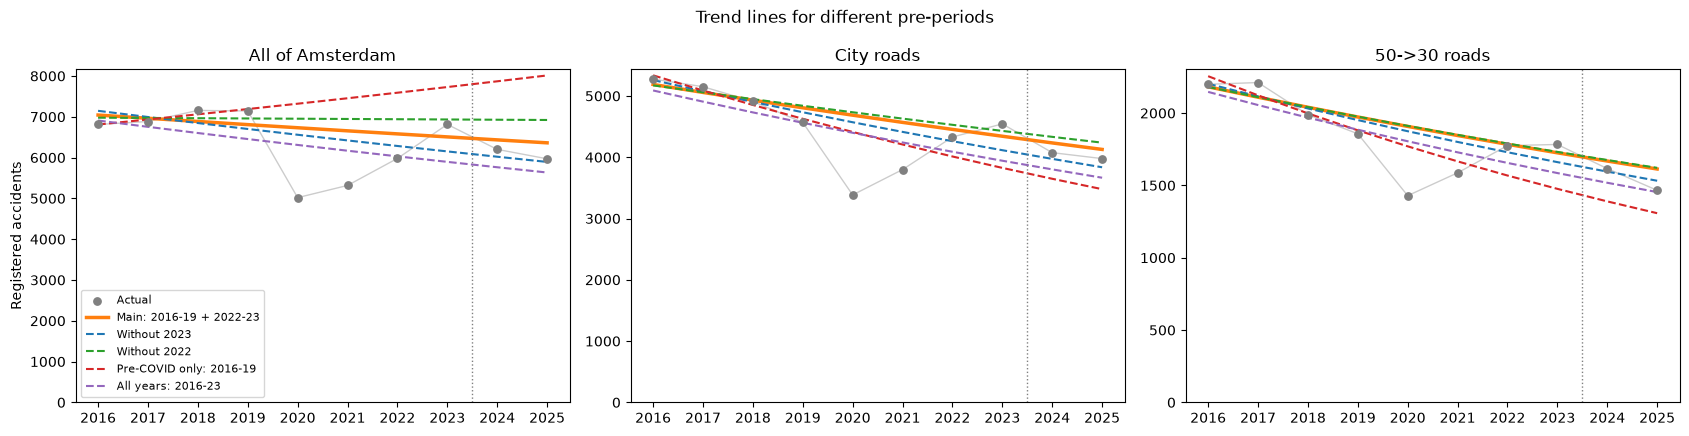

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
for ax, name in zip(axes, counts.columns):
    y = counts[name]
    ax.plot(y.index, y.values, color="grey", lw=1, alpha=0.4)
    ax.scatter(y.index, y.values, color="grey", s=28, zorder=3, label="Actual")
    for label, years in pre_periods.items():
        p = predict(fit_poisson_trend(years, y.loc[years]), line_years)
        main = label.startswith("Main")
        ax.plot(p.index, p["predicted"], color=PERIOD_COLOURS[label], lw=2.5 if main else 1.5,
                ls="-" if main else "--", label=label)
    ax.axvline(CHANGE, color="grey", ls=":", lw=1)
    ax.set_title(name)
    ax.set_xticks(line_years)
    ax.set_ylim(bottom=0)
axes[0].set_ylabel("Registered accidents")
axes[0].legend(loc="lower left", fontsize=8)
fig.suptitle("Trend lines for different pre-periods")
fig.tight_layout()
fig.savefig("RQ5_sensitivity_trends.png", dpi=150)
plt.show()

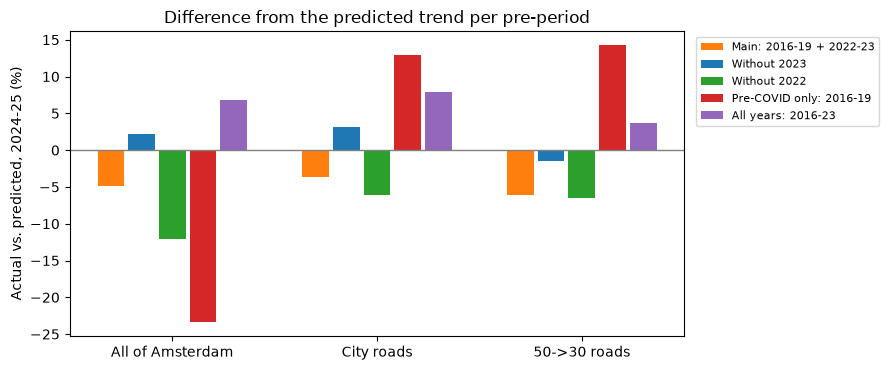

In [10]:
fig, ax = plt.subplots(figsize=(9, 3.8))
width = 0.15
for j, label in enumerate(pre_periods):
    values = sensitivity.xs(label, level="pre-period").loc[counts.columns, "difference_%"]
    x = np.arange(len(counts.columns)) + (j - 2) * width
    ax.bar(x, values, width=width - 0.02, color=PERIOD_COLOURS[label], label=label)
ax.axhline(0, color="grey", lw=1)
ax.set_xticks(range(len(counts.columns)), counts.columns)
ax.set_ylabel("Actual vs. predicted, 2024-25 (%)")
ax.set_title("Difference from the predicted trend per pre-period")
ax.legend(fontsize=8, ncol=1, bbox_to_anchor=(1.01, 1), loc="upper left")
fig.tight_layout()
fig.savefig("RQ5_sensitivity_difference.png", dpi=150)
plt.show()